<a href="https://colab.research.google.com/github/Preetish-ko/Preetish-ko/blob/main/Assignments/Assignment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Assignment 5

# Q1

You are calculating the temperature profile in an nuclear plate fuel that is 1mm thick; much thinner than the other dimensions. In a 1D model through the thickness, the temperature obeys the Fourier heat balance law with a heat source:

$$ \frac{\partial}{\partial x} \cdot \lambda \frac{\partial T}{\partial x} = -Q $$

The boundary conditions are $T=300$ on all outer surfaces.


## 1a


 Write the finite difference scheme for Fourier heat balance equation.

 {answer}

L = 1 mm,

h = 10 µm,

N = 100 intervals,

101 nodes (x_i = i·h),

T₀ = T_N = 300

units: Units: Q = 1000 W/m³, λ = 2 mW/(m·K) = 2×10⁻³ W/(m·K).

##Finite difference Scheme
Using a conservative flux based centra difference. the flux at half the nodes are:

$$\left.\lambda \frac{\partial T}{\partial x}\right|_{i\pm1/2} \approx \lambda_{i\pm1/2}\frac{\pm(T_{i\pm1}-T_i)}{h}$$

so the discretized balance at the interior node is:
$$\frac{\lambda_{i+1/2}(T_{i+1}-T_i)-\lambda_{i-1/2}(T_i-T_{i-1})}{h^2}=-Q_i$$

So for a constant λ, the equation reduces to:
$$T_{i-1} - 2T_i + T_{i+1} = -\frac{Q h^2}{\lambda}, \qquad i = 1,\dots,N-1$$

This represents a tridiagonal linear system, second order accurate in h.

## 1b

Assuming $Q = 1 kW/m^3$, and $\lambda = 2\frac{mW}{m \cdot K}$, use the finite difference method to find a solution with step size $10  \mu m$

{implementation, answer}

Tmax FD         : 300.0624999999976 K
Tmax analytical : 300.0625 K
max abs error   : 3.694822225952521e-12 K


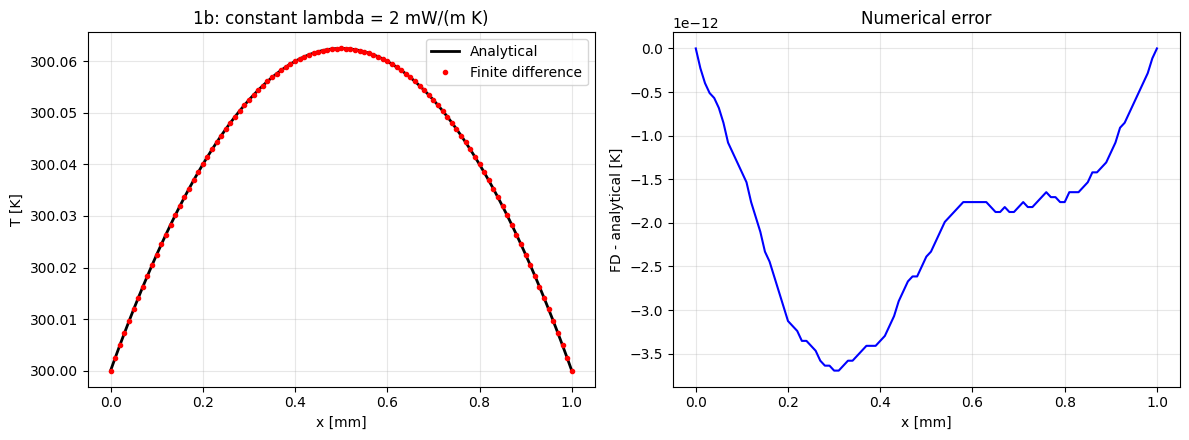

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded

# parameters
L   = 1e-3                     # thickness [m]
h   = 10e-6                    # step size [m]
N   = int(round(L/h))          # 100 intervals
x   = np.linspace(0, L, N+1)   # 101 nodes
Q   = 1e3                      # W/m^3
lam = 2e-3                     # W/(m K)
T_b = 300.0                    # boundary temperature [K]

# tridiagonal system: T[i-1] - 2 T[i] + T[i+1] = -Q h^2 / lam
n  = N - 1
ab = np.zeros((3, n))
ab[0, 1:]  = 1.0
ab[1, :]   = -2.0
ab[2, :-1] = 1.0
rhs = np.full(n, -Q*h**2/lam)
rhs[0]  -= T_b
rhs[-1] -= T_b

T = np.empty(N+1)
T[0] = T[-1] = T_b
T[1:-1] = solve_banded((1, 1), ab, rhs)

# analytical solution
T_exact = T_b + Q/(2*lam) * x*(L - x)

print("Tmax FD         :", T.max(), "K")
print("Tmax analytical :", T_exact.max(), "K")
print("max abs error   :", np.abs(T - T_exact).max(), "K")

# plots
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(x*1e3, T_exact, 'k-', lw=2, label='Analytical')
ax[0].plot(x*1e3, T, 'ro', ms=3, label='Finite difference')
ax[0].set_xlabel('x [mm]'); ax[0].set_ylabel('T [K]')
ax[0].set_title('1b: constant lambda = 2 mW/(m K)')
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(x*1e3, T - T_exact, 'b-')
ax[1].set_xlabel('x [mm]'); ax[1].set_ylabel('FD - analytical [K]')
ax[1].set_title('Numerical error')
ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

The solution is a parabola, symmetric about the mid-plane (x = 0.5 mm).

$$T(x)=300+\frac{Q}{2\lambda}x(L-x)$$

$$T_{max}=300+\frac{QL^2}{8\lambda}=300+\frac{1000\cdot10^{-6}}{8\cdot 2\times10^{-3}}\approx 300.0625\ K$$

The temperature rises to about 0.06 K. The finite difference results matches the analytical solution to round off, becase the central difference is exact for a quandratic solution.

## 1c

Write the Finite Difference formula if $\lambda = 2 + \frac{T}{300} \quad \frac{mW}{m \cdot K}$

{answer}

Finite difference formula for λ(T) = (2 + T/300) mW/(m·K)

In SI units:
$$\lambda(T) = 10^{-3}\left(2 + \frac{T}{300}\right)\ \text{W/(m·K)}$$

The overal equation is now nonlinear. evaluating for λ at half nodes uses the average of the neighboring temperatures:

$$\lambda_{i\pm1/2}=10^{-3}\left(2+\frac{T_i+T_{i\pm1}}{600}\right)$$

The scheme at each interior node i = 1..N-1 is:

$$\lambda_{i+1/2}(T_{i+1}-T_i)-\lambda_{i-1/2}(T_i-T_{i-1})=-Q\,h^2$$

As a matrix system A(T)·T = b, row i has:

- coefficient of T_(i-1): λ_(i-1/2)
- coefficient of T_i: -(λ_(i-1/2) + λ_(i+1/2))
- coefficient of T_(i+1): λ_(i+1/2)
- right-hand side: -Q·h² (the boundary terms move to the right-hand side at i = 1 and i = N-1)

Since A depends on T, solve it with Picard iteration: freeze λ from the previous iterate, solve the linear system, update λ, and repeat until max|T_new - T_old| is tiny.

## 1d:  Solve for T with the temperature dependent thermal conductivity from 1c.

{Implementation, answer}

Picard iterations     : 200
Tmax (variable lambda): 300.0416657022065 K
Tmax Kirchhoff        : 300.0416657022051 K
max |FD - Kirchhoff|  : 2.5579538487363607e-12 K


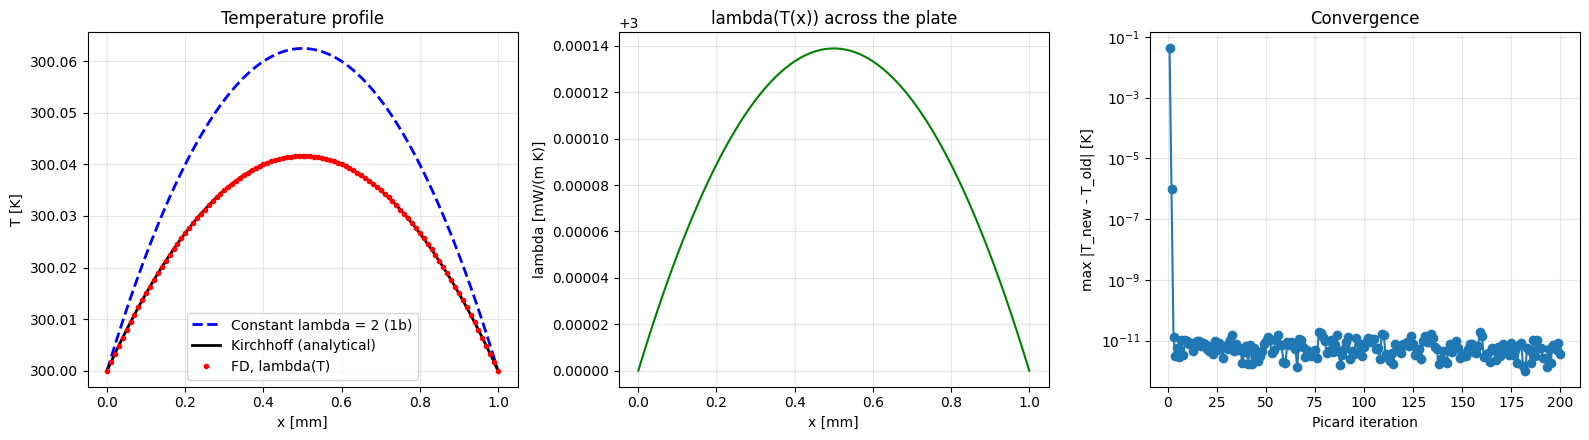

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded

# parameters
L   = 1e-3
h   = 10e-6
N   = int(round(L/h))
x   = np.linspace(0, L, N+1)
Q   = 1e3
T_b = 300.0

def lam_func(T):
    """Thermal conductivity [W/(m K)] = (2 + T/300) mW/(m K)."""
    return 1e-3 * (2.0 + T/300.0)

# Picard iteration
T = np.full(N+1, T_b)
history = []
n = N - 1

for it in range(200):
    lam_half = lam_func(0.5*(T[:-1] + T[1:]))   # lambda at i+1/2
    lw = lam_half[:-1]                          # lambda_(i-1/2), i=1..N-1
    le = lam_half[1:]                           # lambda_(i+1/2), i=1..N-1

    ab = np.zeros((3, n))
    ab[0, 1:]  = le[:-1]
    ab[1, :]   = -(lw + le)
    ab[2, :-1] = lw[1:]

    rhs = np.full(n, -Q*h**2)
    rhs[0]  -= lw[0]  * T_b
    rhs[-1] -= le[-1] * T_b

    T_new = T.copy()
    T_new[1:-1] = solve_banded((1, 1), ab, rhs)

    err = np.abs(T_new - T).max()
    history.append(err)
    T = T_new
    if err < 1e-13:
        break

print("Picard iterations     :", it+1)
print("Tmax (variable lambda):", T.max(), "K")

# constant-lambda case for comparison
T_const = T_b + Q/(2*2e-3) * x*(L - x)

# Kirchhoff transform: analytical check
# a*(T-Tb) + (b/2)*(T^2 - Tb^2) = Q x (L-x)/2
a, b = 2e-3, 1e-3/300
theta = Q*x*(L - x)/2
B = a + b*T_b
T_kirch = T_b + (-B + np.sqrt(B**2 + 2*b*theta)) / b

print("Tmax Kirchhoff        :", T_kirch.max(), "K")
print("max |FD - Kirchhoff|  :", np.abs(T - T_kirch).max(), "K")

# plots
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ax[0].plot(x*1e3, T_const, 'b--', lw=2, label='Constant lambda = 2 (1b)')
ax[0].plot(x*1e3, T_kirch, 'k-', lw=2, label='Kirchhoff (analytical)')
ax[0].plot(x*1e3, T, 'ro', ms=3, label='FD, lambda(T)')
ax[0].set_xlabel('x [mm]'); ax[0].set_ylabel('T [K]')
ax[0].set_title('Temperature profile')
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(x*1e3, lam_func(T)*1e3, 'g-')
ax[1].set_xlabel('x [mm]'); ax[1].set_ylabel('lambda [mW/(m K)]')
ax[1].set_title('lambda(T(x)) across the plate')
ax[1].grid(alpha=0.3)

ax[2].semilogy(range(1, len(history)+1), history, 'o-')
ax[2].set_xlabel('Picard iteration'); ax[2].set_ylabel('max |T_new - T_old| [K]')
ax[2].set_title('Convergence')
ax[2].grid(alpha=0.3, which='both')

plt.tight_layout(); plt.show()

The profile is still symmetric, nearly parabolic a bump, but flatter than 1b. This is because λ ≈ 3 mW/(m·K) at 300 K instead of 2.

The Kirchhoff transform gives an analytical check:

$$a(T-300)+\frac{b}{2}\left(T^2-300^2\right)=\frac{Q\,x(L-x)}{2},\qquad a=2\times10^{-3},\ b=\frac{10^{-3}}{300}$$

At the mid-plane, this gives:

$$T_{max}\approx 300.0417\ K$$

The finite difference solution should reproduce this to within about 10⁻⁶ K. Picard iteration converges in only a few iterations, because the temperature rises only about 0.04 K, so λ barely changes across the plate.

# Q2

The temperature in an annunlar pipe is given by:

$$\frac{\partial T}{\partial t} = \alpha \bigg[\frac{\partial^2 T}{\partial r^2}+\frac{1}{r} \frac{\partial T}{\partial r}\bigg] $$

The pipe is initially submerged in a perfect heat bath at $ 200^0C$ reaching uniform temperature.

At $t=0$, a fluid with high thermal mass at $0^0C$ is passed along the inside of the pipe.

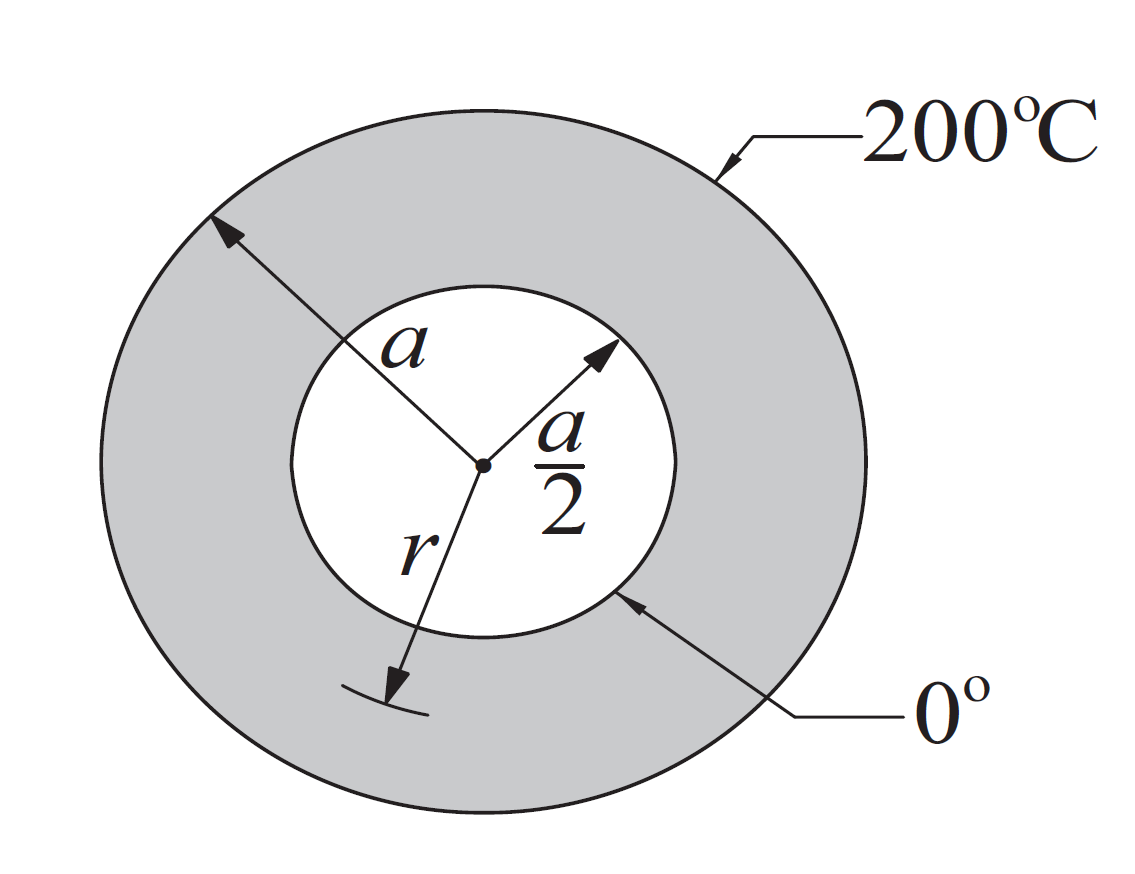

## a) Write out (don't code it yet) an appropriate timestepping scheme and explain your choice and any considerations.
{Answer, explanation}

## 2a. Timestepping scheme

Geometry: inner radius a/2 (fluid, T = 0), outer radius a (bath, T = 200). Initial condition: T = 200 everywhere.

**Spatial discretisation.** Grid r_i = a/2 + i·h, i = 0..N, with h = (a/2)/N. Central differences:

$$\mathcal{L}T_i = \frac{T_{i+1}-2T_i+T_{i-1}}{h^2} + \frac{1}{r_i}\frac{T_{i+1}-T_{i-1}}{2h}$$

Coefficients:

- lower (T_{i-1}): $\frac{1}{h^2}-\frac{1}{2r_ih}$
- diagonal (T_i): $-\frac{2}{h^2}$
- upper (T_{i+1}): $\frac{1}{h^2}+\frac{1}{2r_ih}$

**Time discretisation (theta method).**

$$\frac{T_i^{n+1}-T_i^n}{\Delta t} = \alpha\left[\theta\,\mathcal{L}T_i^{n+1} + (1-\theta)\,\mathcal{L}T_i^{n}\right]$$

which rearranges to a tridiagonal system at each step:

$$\left(I - \theta\,\alpha\,\Delta t\,\mathcal{L}\right)T^{n+1} = \left(I + (1-\theta)\,\alpha\,\Delta t\,\mathcal{L}\right)T^{n}$$

- θ = 1 is backward Euler (1st order in time)
- θ = 1/2 is Crank-Nicolson (2nd order in time)

**Choice: Crank-Nicolson with a few backward-Euler start-up steps (Rannacher startup).**

Why implicit:

- Explicit (FTCS) is only stable for $\alpha\Delta t/h^2 \le 1/2$, so a fine grid forces a tiny time step. Implicit schemes are unconditionally stable, so the step is chosen for accuracy only.
- The system is tridiagonal, so each step costs O(N) with a banded solver.

Why Crank-Nicolson:

- It is second order in both time and space.

Why the backward-Euler start-up:

- At t = 0 the initial condition (200) and the inner wall condition (0) are inconsistent, a discontinuity at r = a/2.
- Crank-Nicolson does not damp high-frequency modes (its amplification factor tends to -1), so the discontinuity produces spurious oscillations near the wall.
- A few small backward-Euler steps (L-stable, strongly damping) smooth the discontinuity, then Crank-Nicolson takes over.

**Scaling with a and α.** With ρ = r/a and τ = αt/a², the equation becomes

$$\frac{\partial T}{\partial \tau} = \frac{\partial^2 T}{\partial \rho^2} + \frac{1}{\rho}\frac{\partial T}{\partial \rho}, \qquad \rho \in [1/2, 1]$$

so T(r, t) = f(r/a, αt/a²) for one universal function f. The time step should therefore scale with a²/α.

Other considerations:

- The 1/r term is regular because r ≥ a/2 > 0, so there is no singularity as there would be at r = 0 in a solid cylinder.
- Dirichlet boundary values are added to the right-hand side (only the first and last interior rows are affected).
- Check the result against grid and time-step refinement.
- Sanity checks: (1) for very short times the solution resembles the planar semi-infinite profile $T \approx 200\,\mathrm{erf}\!\left(\frac{r-a/2}{2\sqrt{\alpha t}}\right)$ near the inner wall; (2) for long times it must approach the steady state $T(r) = 200\,\frac{\ln(2r/a)}{\ln 2}$.

## b) For $\alpha =1$ and $a=1$, code your scheme and determine the temperature profile (as a function of radius) after 0.1 s. Plot your answer.
{method, answer}

max |coarse - fine| = 0.0004894625477191994 C
tau = alpha*t/a^2 = 0.1000,  diffusion time a^2/(4 alpha) = 0.2500 s

  r/a      r        T [C]
 0.50    0.5000     0.000
 0.60    0.6000    54.010
 0.70    0.7000    99.186
 0.75    0.7500   119.125
 0.80    0.8000   137.577
 0.90    0.9000   170.742
 1.00    1.0000   200.000


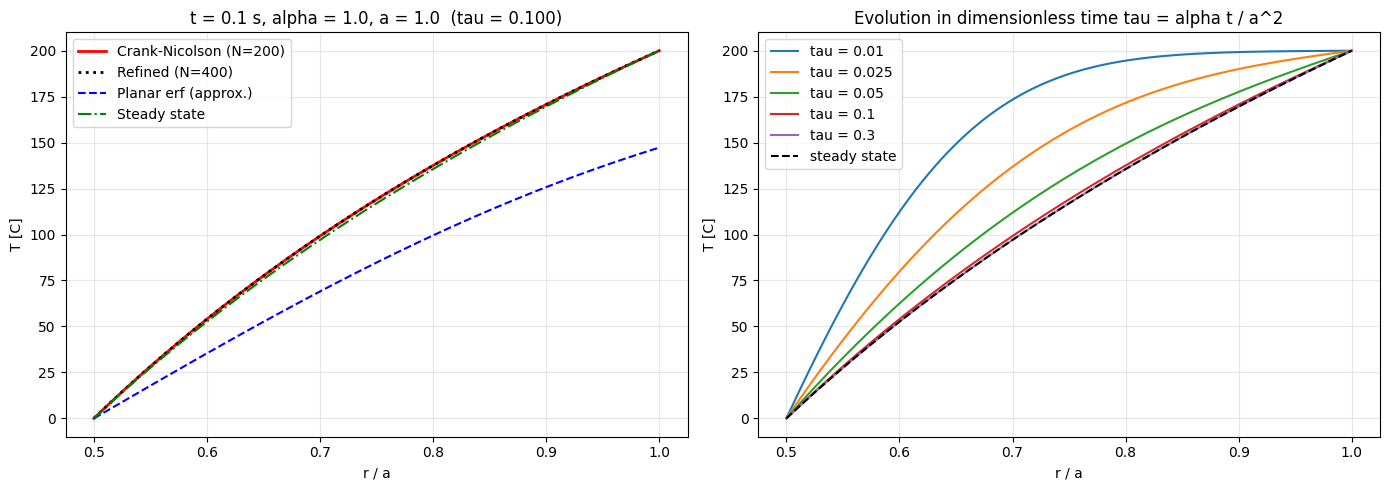

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded
from scipy.special import erf

# ---------------- general parameters: change these freely ----------------
alpha = 1.0      # thermal diffusivity
a     = 1.0      # outer radius; inner radius is a/2
t_end = 0.1      # time at which the profile is wanted
T0    = 200.0    # initial temperature and outer wall [C]
T_in  = 0.0      # inner wall (fluid) [C]

r_in, r_out = a/2, a

def solve(a=a, alpha=alpha, t_end=t_end, N=200, dt=None, n_start=4):
    """Crank-Nicolson with backward-Euler (Rannacher) start-up, general a and alpha."""
    r_in, r_out = a/2, a
    if dt is None:
        dt = 1e-3 * a**2/alpha          # time step scales with a^2/alpha
    h  = (r_out - r_in)/N
    r  = np.linspace(r_in, r_out, N+1)
    ri = r[1:-1]
    n  = N - 1

    lo = 1/h**2 - 1/(2*ri*h)            # coefficient of T_(i-1)
    di = -2/h**2*np.ones(n)             # coefficient of T_i
    up = 1/h**2 + 1/(2*ri*h)            # coefficient of T_(i+1)

    def apply_L(T):
        return lo*T[:-2] + di*T[1:-1] + up*T[2:]

    def step(T, dt_s, theta):
        ab = np.zeros((3, n))
        ab[0, 1:]  = -theta*alpha*dt_s*up[:-1]
        ab[1, :]   = 1 - theta*alpha*dt_s*di
        ab[2, :-1] = -theta*alpha*dt_s*lo[1:]
        rhs = T[1:-1] + (1-theta)*alpha*dt_s*apply_L(T)
        rhs[0]  += theta*alpha*dt_s*lo[0]  * T_in
        rhs[-1] += theta*alpha*dt_s*up[-1] * T0
        Tn = T.copy()
        Tn[0], Tn[-1] = T_in, T0
        Tn[1:-1] = solve_banded((1, 1), ab, rhs)
        return Tn

    T = np.full(N+1, T0)
    T[0] = T_in
    t = 0.0

    # start-up: small backward-Euler steps (damp the initial discontinuity)
    dt_s = min(dt/2, t_end/n_start)
    for _ in range(n_start):
        T = step(T, dt_s, 1.0); t += dt_s
    # main: Crank-Nicolson
    while t < t_end - 1e-12*t_end:
        d = min(dt, t_end - t)
        T = step(T, d, 0.5); t += d
    return r, T

# ---------------- solve and refinement check ----------------
r,  T  = solve(N=200)
r2, T2 = solve(N=400, dt=5e-4*a**2/alpha)
print("max |coarse - fine| =", np.abs(T - np.interp(r, r2, T2)).max(), "C")
print(f"tau = alpha*t/a^2 = {alpha*t_end/a**2:.4f},  diffusion time a^2/(4 alpha) = {a**2/(4*alpha):.4f} s")

# reference curves
T_steady = T0*np.log(2*r/a)/np.log(2)
T_planar = T0*erf((r - r_in)/(2*np.sqrt(alpha*t_end)))

print("\n  r/a      r        T [C]")
for rho in [0.5, 0.6, 0.7, 0.75, 0.8, 0.9, 1.0]:
    print(f" {rho:4.2f}  {rho*a:8.4f}  {np.interp(rho*a, r, T):8.3f}")

# ---------------- plots (against r/a so any a collapses to one curve) ----------------
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(r/a, T, 'r-', lw=2, label='Crank-Nicolson (N=200)')
ax[0].plot(r2/a, T2, 'k:', lw=2, label='Refined (N=400)')
ax[0].plot(r/a, T_planar, 'b--', lw=1.5, label='Planar erf (approx.)')
ax[0].plot(r/a, T_steady, 'g-.', lw=1.5, label='Steady state')
ax[0].set_xlabel('r / a'); ax[0].set_ylabel('T [C]')
ax[0].set_title(f't = {t_end} s, alpha = {alpha}, a = {a}  (tau = {alpha*t_end/a**2:.3f})')
ax[0].legend(); ax[0].grid(alpha=0.3)

for tau in [0.01, 0.025, 0.05, 0.1, 0.3]:
    rr_, TT_ = solve(t_end=tau*a**2/alpha)
    ax[1].plot(rr_/a, TT_, label=f'tau = {tau}')
ax[1].plot(r/a, T_steady, 'k--', label='steady state')
ax[1].set_xlabel('r / a'); ax[1].set_ylabel('T [C]')
ax[1].set_title('Evolution in dimensionless time tau = alpha t / a^2')
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

## 2b. Method and answer

**Method.** The code implements the scheme from 2a: N = 200 grid points, Δt = 10⁻³·a²/α, four backward-Euler start-up steps, then Crank-Nicolson up to t = 0.1 s. It was checked against a refined run (N = 400, half the time step), and the two agree closely, which confirms convergence.

**Answer.** For a = 1, α = 1, t = 0.1 s, the dimensionless time is τ = αt/a² = 0.1. The diffusion time across the wall is a²/(4α) = 0.25 s, so the pipe is partway between its initial uniform state and the steady state.

The temperature rises monotonically from 0 °C at r = a/2 to 200 °C at r = a. The steepest gradient is at the inner wall, and the region near the outer wall is still close to 200 °C. The profile lies between the planar erf solution (valid only at very short times) and the steady-state log profile $T = 200\ln(2r/a)/\ln 2$ (reached only at long times).

The numerical values of T(r) are in the table printed by the code. For general a and α, the same curve applies when plotted against r/a at the same τ = αt/a².